# Iris Flower Classification
**Oasis Infobyte Internship · Data Science · Task 1**

Goal: train a model that identifies the species of an iris flower (setosa, versicolor or virginica)
from four measurements: sepal length, sepal width, petal length and petal width.

Steps: load data → exploratory data analysis → visualisation → feature selection → train/test split →
train 4 classifiers → evaluate → pick the best model.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# scikit-learn: data, splitting, models and metrics
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

sns.set_theme(style="whitegrid")
OUT = Path("outputs")          # every plot is also saved here for the README
OUT.mkdir(exist_ok=True)
RANDOM_STATE = 42              # fixed seed so results are reproducible

## 1. Load the dataset
The Iris dataset ships with scikit-learn, so `load_iris()` needs no download.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df["species"] = df["target"].map(dict(enumerate(iris.target_names)))
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


## 2. Exploratory data analysis
Shape, data types, missing values and descriptive statistics.

In [3]:
print("Shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values per column:\n", df.isnull().sum())
print("\nRows per species:\n", df["species"].value_counts())

Shape: (150, 6)

Data types:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
target                 int64
species                  str
dtype: object

Missing values per column:
 sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
species              0
dtype: int64

Rows per species:
 species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [4]:
# Descriptive statistics for the four numeric features
df.drop(columns="target").describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


In [5]:
# Mean of each feature per species: a first hint at which features separate the classes
df.drop(columns="target").groupby("species").mean().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.59,2.97,5.55,2.03


**Observations:** 150 rows, 4 numeric features, no missing values, and a perfectly balanced
target (50 flowers per species), so accuracy is a fair headline metric.

## 3. Visualisations
### 3.1 Pairplot of every feature pair, coloured by species

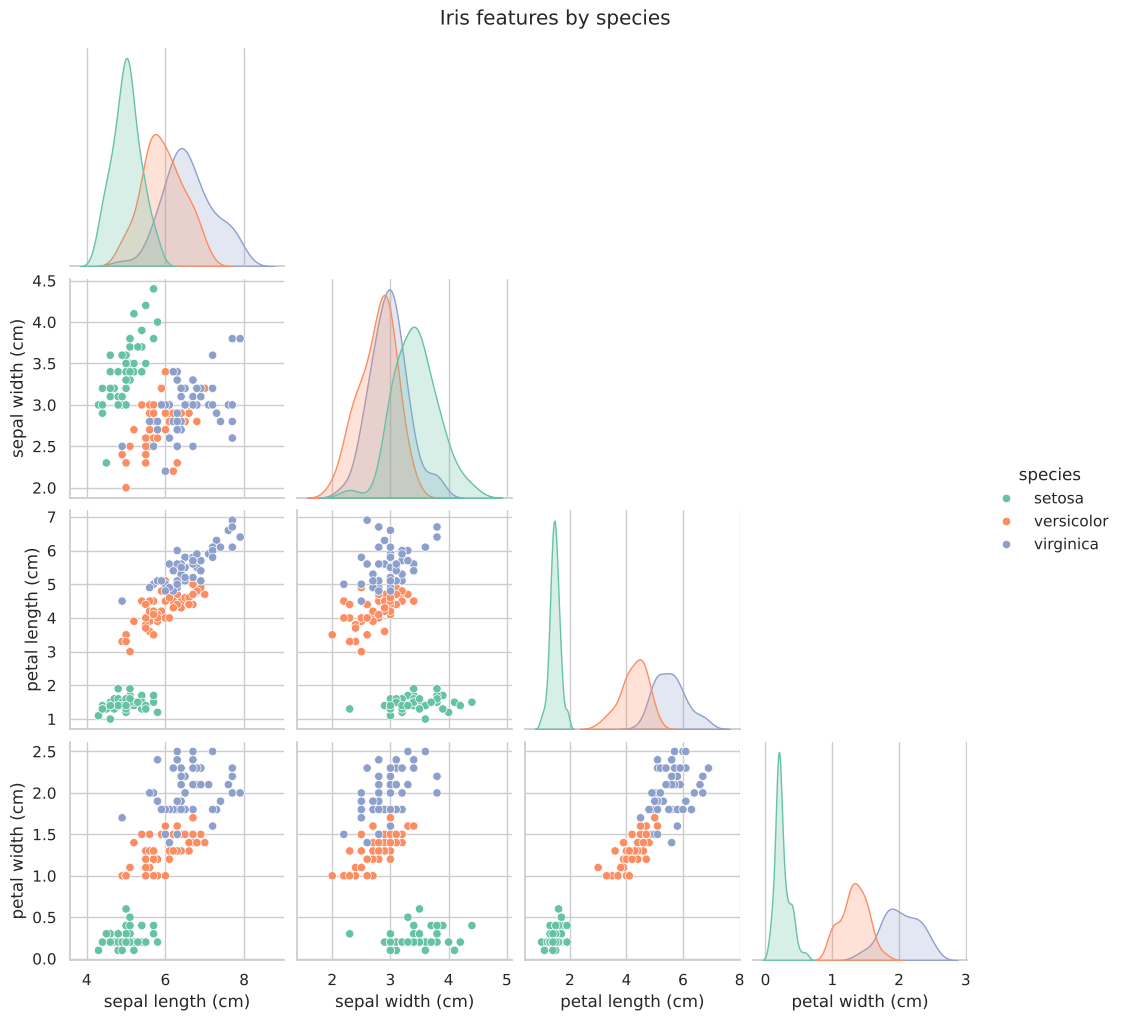

In [6]:
g = sns.pairplot(df.drop(columns="target"), hue="species", corner=True, palette="Set2")
g.figure.suptitle("Iris features by species", y=1.02)
g.savefig(OUT / "pairplot.png", dpi=120, bbox_inches="tight")
plt.show()

### 3.2 Box plot of each feature per species

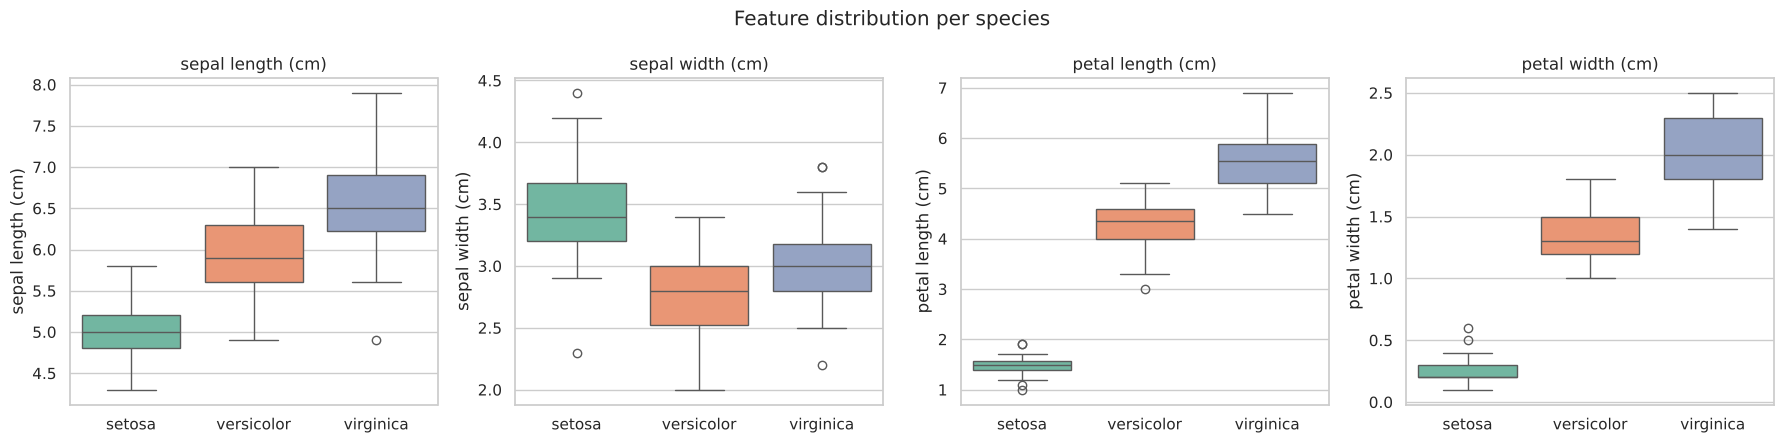

In [7]:
features = iris.feature_names
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, features):
    sns.boxplot(data=df, x="species", y=col, hue="species", palette="Set2", ax=ax, legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Feature distribution per species")
fig.tight_layout()
fig.savefig(OUT / "boxplots.png", dpi=120, bbox_inches="tight")
plt.show()

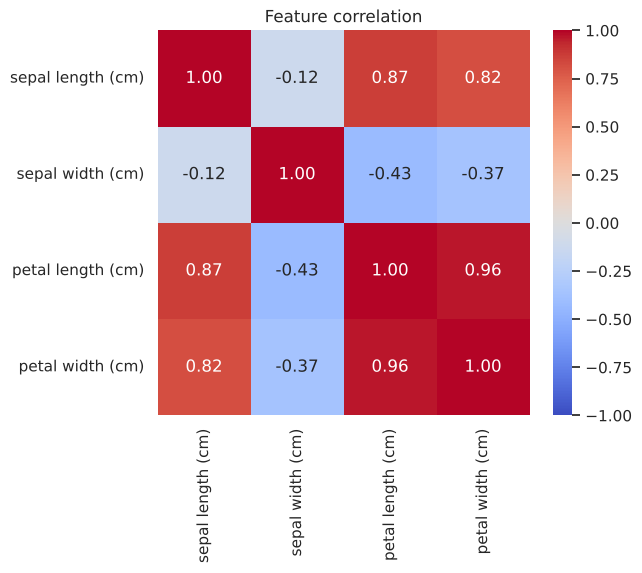

In [8]:
# Correlation between features
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Feature correlation")
plt.savefig(OUT / "correlation_heatmap.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Feature selection: which features separate the species best?
We check this two ways: visually (plots above) and with a Random Forest's feature importance.

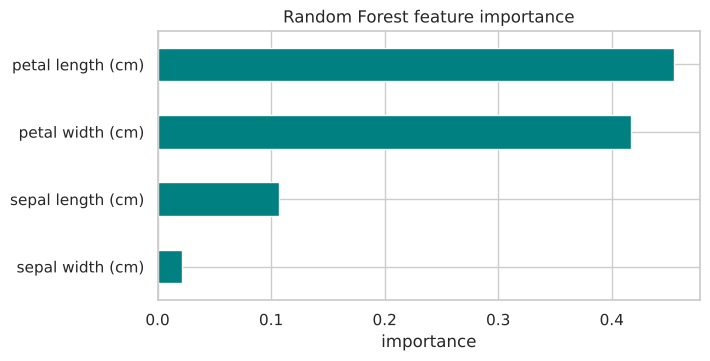

petal length (cm)    0.455
petal width (cm)     0.417
sepal length (cm)    0.107
sepal width (cm)     0.021
dtype: float64

In [9]:
rf_probe = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(df[features], df["target"])
importance = pd.Series(rf_probe.feature_importances_, index=features).sort_values()
importance.plot.barh(color="teal", figsize=(7, 3.5), title="Random Forest feature importance")
plt.xlabel("importance")
plt.savefig(OUT / "feature_importance.png", dpi=120, bbox_inches="tight")
plt.show()
importance.sort_values(ascending=False).round(3)

**Discussion:**
- **Petal length and petal width** are by far the most informative features. In the pairplot and box plots
  setosa is completely separated by either one, and versicolor and virginica overlap only slightly.
- **Sepal width** carries the least information; its ranges overlap heavily across all three species.
- Petal length and width are highly correlated (≈0.96), so they carry largely the same signal.

All four features are kept for modelling because the dataset is tiny and nothing needs to be dropped
for speed, but petal measurements alone would already give very high accuracy.

## 5. Train/test split (80/20)
`stratify=y` keeps the 1:1:1 species ratio in both sets.

In [10]:
X = df[features]
y = df["species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (120, 4)  Test: (30, 4)


## 6. Train four classifiers
Distance-based and linear models (KNN, Logistic Regression) get standardised features via a pipeline;
tree models do not need scaling.

In [11]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "K-Nearest Neighbours": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
}

results = []
for name, model in models.items():
    model.fit(X_train, y_train)
    test_acc = accuracy_score(y_test, model.predict(X_test))
    # 5-fold cross-validation on the training set gives a more stable estimate than one 30-row test set
    cv = cross_val_score(model, X_train, y_train, cv=5)
    results.append({"model": name, "test_accuracy": test_acc, "cv_mean": cv.mean(), "cv_std": cv.std()})

results = pd.DataFrame(results).sort_values(["test_accuracy", "cv_mean"], ascending=False).reset_index(drop=True)
results.to_csv(OUT / "model_comparison.csv", index=False)
results.round(4)

,model,test_accuracy,cv_mean,cv_std
0,K-Nearest Neighbours,0.9333,0.9667,0.0312
1,Logistic Regression,0.9333,0.9583,0.0264
2,Decision Tree,0.9333,0.9417,0.0204
3,Random Forest,0.9000,0.9500,0.0167


## 7. Evaluate each model: confusion matrix and classification report

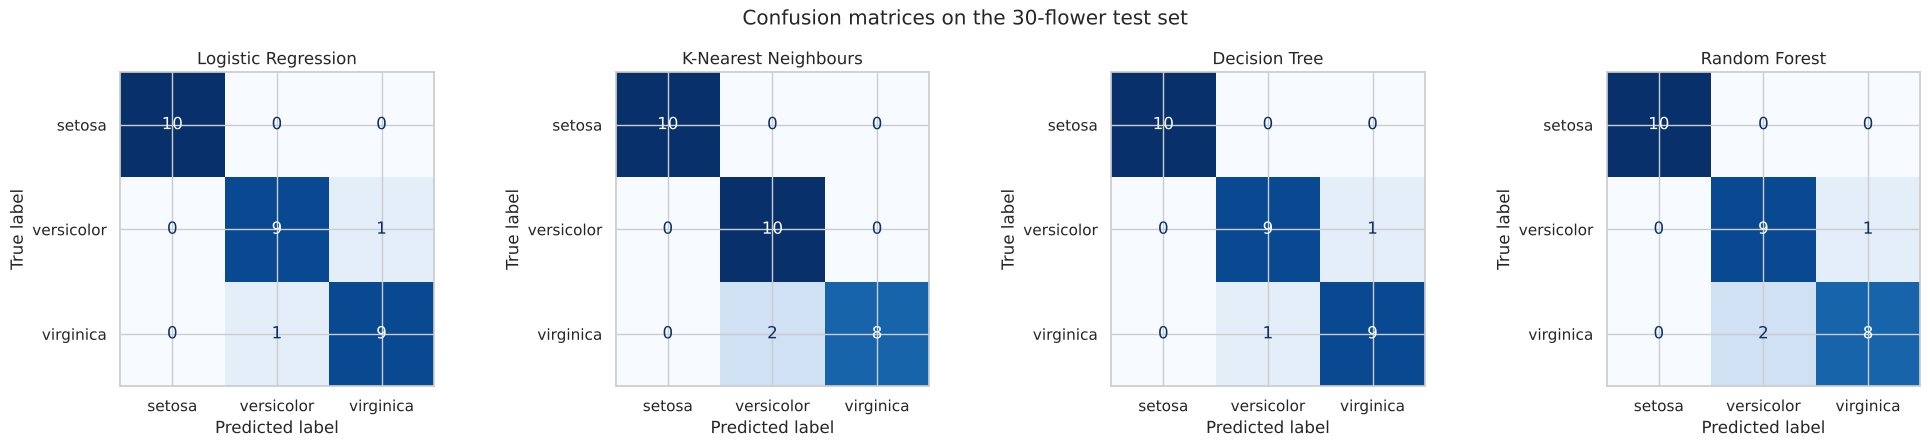

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
fig.suptitle("Confusion matrices on the 30-flower test set")
fig.tight_layout()
fig.savefig(OUT / "confusion_matrices.png", dpi=120, bbox_inches="tight")
plt.show()

In [13]:
reports = []
for name, model in models.items():
    report = classification_report(y_test, model.predict(X_test), digits=3)
    print(f"===== {name} =====\n{report}")
    reports.append(f"===== {name} =====\n{report}")
(OUT / "classification_reports.txt").write_text("\n".join(reports))

===== Logistic Regression =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

===== K-Nearest Neighbours =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.833     1.000     0.909        10
   virginica      1.000     0.800     0.889        10

    accuracy                          0.933        30
   macro avg      0.944     0.933     0.933        30
weighted avg      0.944     0.933     0.933        30

===== Decision Tree =====
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     

1640

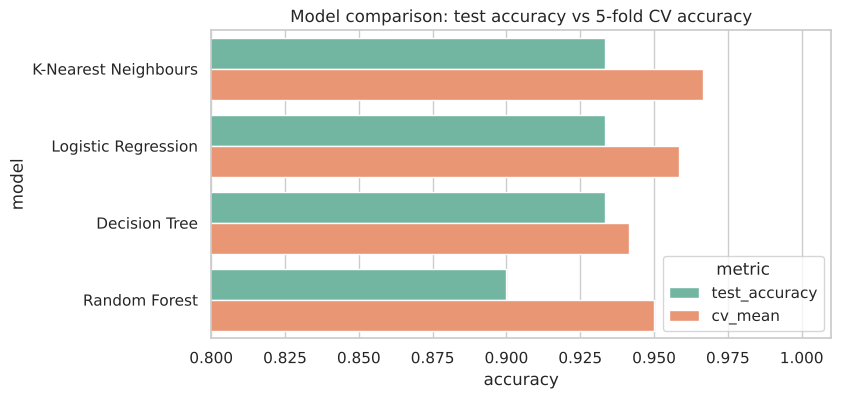

In [14]:
plt.figure(figsize=(8, 4))
plot_df = results.melt(id_vars="model", value_vars=["test_accuracy", "cv_mean"], var_name="metric", value_name="accuracy")
sns.barplot(data=plot_df, x="accuracy", y="model", hue="metric", palette="Set2")
plt.xlim(0.8, 1.01)
plt.title("Model comparison: test accuracy vs 5-fold CV accuracy")
plt.savefig(OUT / "model_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 8. Best model and justification

In [15]:
best = results.iloc[0]
print(f"Best model: {best['model']}  |  test accuracy = {best['test_accuracy']:.3f}  |  "
      f"CV accuracy = {best['cv_mean']:.3f} ± {best['cv_std']:.3f}")

Best model: K-Nearest Neighbours  |  test accuracy = 0.933  |  CV accuracy = 0.967 ± 0.031


**Choice: K-Nearest Neighbours (k = 5, standardised features).**

- KNN, Logistic Regression and the Decision Tree tie on test accuracy (93.3%, i.e. 2 mistakes out of 30),
  so the test set alone cannot separate them. The tie-breaker is 5-fold cross-validation on the
  training data, where KNN scores highest (≈96.7%), so its performance is the most consistent.
- The only errors any model makes are between **versicolor and virginica**, the two species whose petal
  measurements overlap; setosa is always classified perfectly.
- KNN suits this data: the species form compact, well-separated clusters in feature space (see the
  pairplot), which is exactly what a nearest-neighbour vote exploits. It is also simple, with one
  hyperparameter.

Logistic Regression is a very close second and would be the pick if interpretability (per-feature
coefficients) mattered more. On a dataset this small the model choice matters far less than the fact
that petal measurements make the species almost linearly separable.

In [16]:
# Example prediction with the chosen model on a new flower
best_model = models[best["model"]]
sample = pd.DataFrame([[5.1, 3.5, 1.4, 0.2], [6.7, 3.0, 5.2, 2.3]], columns=features)
for row, pred in zip(sample.values, best_model.predict(sample)):
    print(row, "->", pred)

[5.1 3.5 1.4 0.2] -> setosa
[6.7 3.  5.2 2.3] -> virginica
